#Proyecto Final

##Analisis de Desempeño de Modelos

###Descarga de Datos

El repo ya existe, se omite la descarga.

Conteo de imágenes:
    test / advanced  : 50
    test / early     : 50
    test / normal    : 100
   train / advanced  : 150
   train / early     : 150
   train / normal    : 300
  TOTAL: 800


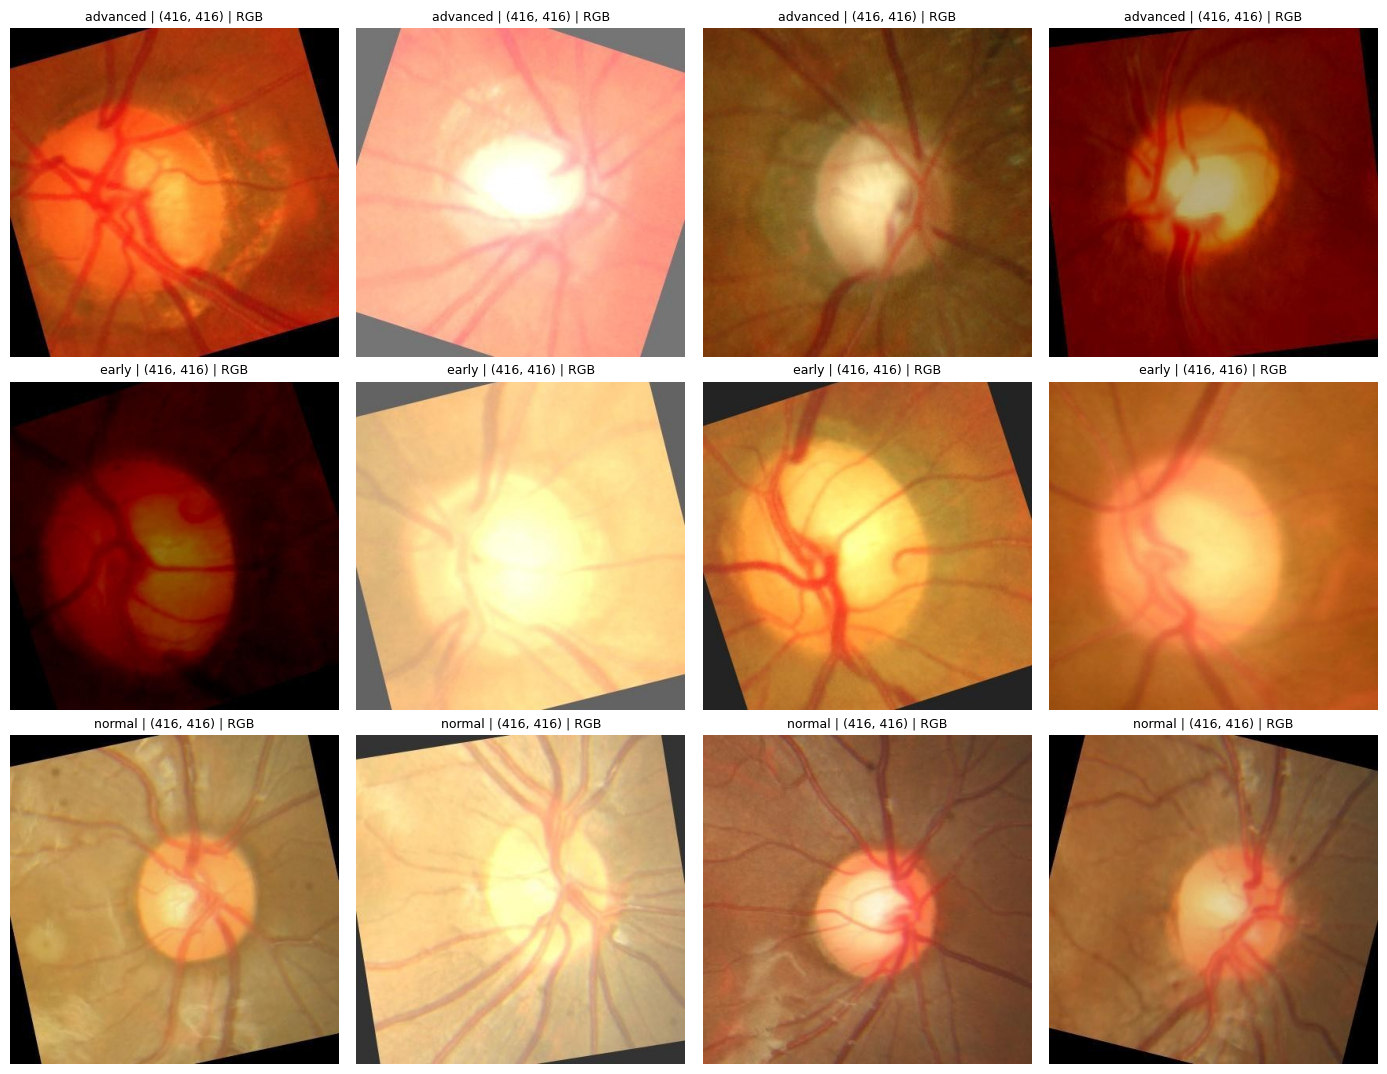

In [5]:
# ============ Descarga y verificación de MOONDREAM_STAGED ============
import os
from pathlib import Path

REPO_URL = "https://github.com/fhurtadoa/ProyectoDL-Grupo2-Glaucoma.git"
REPO_DIR = "/content/ProyectoDL-Grupo2-Glaucoma"
CARPETA  = "data/MOONDREAM_STAGED"

if not os.path.exists(REPO_DIR):
    !git clone --depth 1 --filter=blob:none --sparse {REPO_URL} {REPO_DIR}
    !git -C {REPO_DIR} sparse-checkout set {CARPETA}
else:
    print("El repo ya existe, se omite la descarga.")

DATA_DIR = Path(REPO_DIR) / CARPETA
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# --- Conteo por split y clase ---
print("\nConteo de imágenes:")
total = 0
for split in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    for cls in sorted(p for p in split.iterdir() if p.is_dir()):
        n = sum(1 for f in cls.rglob("*") if f.suffix.lower() in EXTS)
        total += n
        print(f"  {split.name:>6} / {cls.name:<10}: {n}")
print(f"  TOTAL: {total}")

# --- Muestras visuales por clase (train) ---
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
train_dir = next(p for p in DATA_DIR.iterdir() if p.name.lower() == "train")
clases = sorted(p for p in train_dir.iterdir() if p.is_dir())

fig, axes = plt.subplots(len(clases), 4, figsize=(14, 3.6 * len(clases)))
for i, cls in enumerate(clases):
    archivos = [f for f in cls.rglob("*") if f.suffix.lower() in EXTS]
    for j, f in enumerate(random.sample(archivos, min(4, len(archivos)))):
        img = Image.open(f)
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{cls.name} | {img.size} | {img.mode}", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

### Auditoria Fuga de Datos

clase  advanced  early  normal
split                         
test         50     50     100
train       150    150     300 

Ejemplos de nombres:
  normal: ['moon_tr_norm_0000.jpg', 'moon_tr_norm_0001.jpg', 'moon_tr_norm_0002.jpg', 'moon_tr_norm_0003.jpg', 'moon_tr_norm_0004.jpg']
  early: ['moon_tr_0000.jpg', 'moon_tr_0001.jpg', 'moon_tr_0002.jpg', 'moon_tr_0003.jpg', 'moon_tr_0004.jpg']
  advanced: ['moon_tr_0000.jpg', 'moon_tr_0001.jpg', 'moon_tr_0002.jpg', 'moon_tr_0003.jpg', 'moon_tr_0004.jpg']

[1] Duplicados exactos train<->test: 12

[2] Atajos por clase (train):
          pad_negro  pad_gris       R       G      B    R/B
clase                                                      
advanced       0.47      0.17  161.43   98.72  46.72  16.84
early          0.48      0.19  161.30  102.69  55.09  14.81
normal         0.49      0.15  167.07  115.61  74.84   6.62

[3] Similitud coseno al vecino más cercano:
  test -> train : mediana=0.916  p90=0.945  max=1.000
  train -> train: media

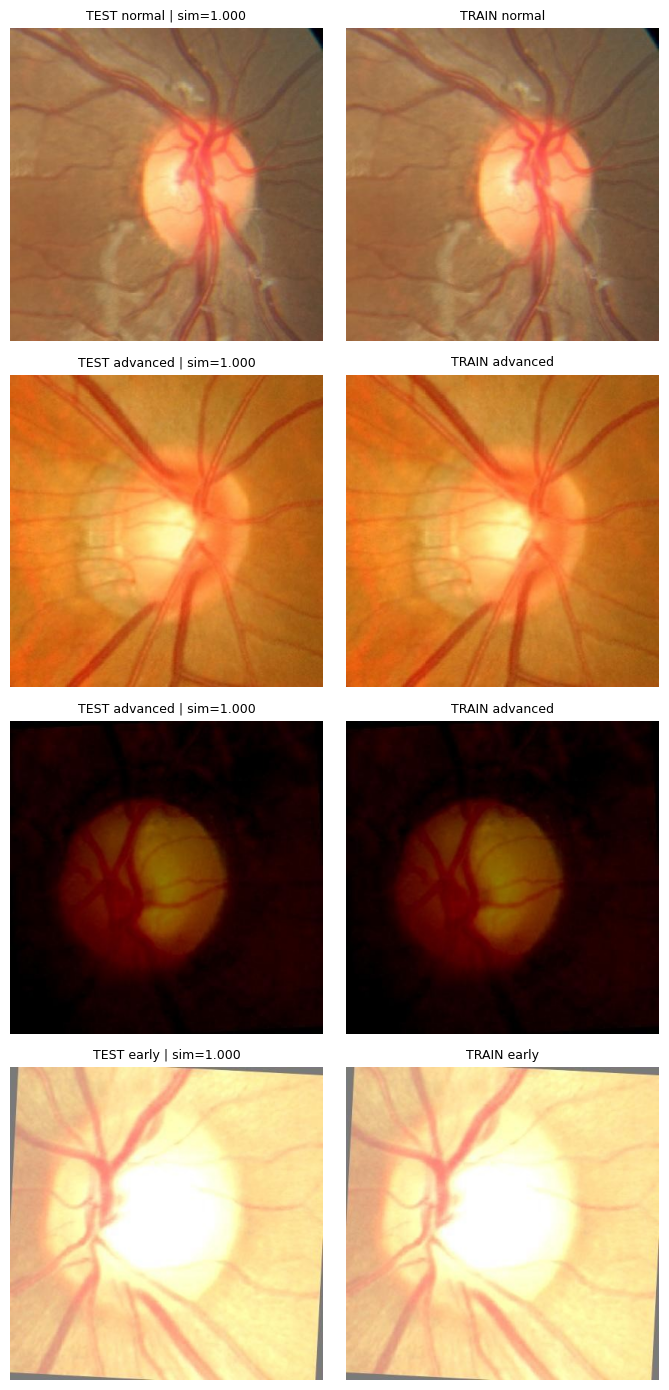

In [6]:
# ============ Auditoría de fuga de datos  ============
import hashlib
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
from PIL import Image

# --- Tabla de archivos ---
rows = []
for split in ["train", "test"]:
    for cls in ["normal", "early", "advanced"]:
        for f in sorted((DATA_DIR / split / cls).rglob("*")):
            if f.suffix.lower() in EXTS:
                rows.append({"split": split, "clase": cls, "ruta": f})
df = pd.DataFrame(rows)
print(df.groupby(["split", "clase"]).size().unstack(), "\n")

# --- Nombres de archivo (¿indican paciente u ojo?) ---
print("Ejemplos de nombres:")
for cls in ["normal", "early", "advanced"]:
    print(f"  {cls}:", [p.name for p in df[(df.split == "train") & (df.clase == cls)].ruta.head(5)])

# --- 1) Duplicados exactos entre train y test ---
df["md5"] = df.ruta.map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())
cruce = df.groupby("md5").filter(lambda g: g.split.nunique() > 1)
print(f"\n[1] Duplicados exactos train<->test: {cruce.md5.nunique()}")

# --- 2) Atajos: relleno de esquinas y color por clase ---
def stats(p):
    img = np.asarray(Image.open(p).convert("RGB")).astype(float)
    esq = [img[:4, :4], img[:4, -4:], img[-4:, :4], img[-4:, -4:]]
    cm = [e.reshape(-1, 3).mean(0) for e in esq]
    negro = any(m.max() < 20 for m in cm)
    gris = any((55 <= m.mean() <= 100) and (m.max() - m.min() < 8) for m in cm)
    R, G, B = img.reshape(-1, 3).mean(0)
    return pd.Series({"pad_negro": negro, "pad_gris": gris, "R": R, "G": G, "B": B})

df = pd.concat([df, df.ruta.map(stats).apply(pd.Series) if False else df.ruta.apply(stats)], axis=1)
df["R/B"] = df.R / df.B
print("\n[2] Atajos por clase (train):")
print(df[df.split == "train"].groupby("clase")[["pad_negro", "pad_gris", "R", "G", "B", "R/B"]].mean().round(2))

# --- 3) Vecinos más cercanos train<->test con embeddings (ResNet-18) ---
device = "cuda" if torch.cuda.is_available() else "cpu"
net = resnet18(weights=ResNet18_Weights.DEFAULT)
net.fc = torch.nn.Identity()
net.eval().to(device)
tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def embed(paths, bs=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), bs):
            x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i + bs]]).to(device)
            out.append(torch.nn.functional.normalize(net(x), dim=1).cpu())
    return torch.cat(out)

tr = df[df.split == "train"].reset_index(drop=True)
te = df[df.split == "test"].reset_index(drop=True)
Etr, Ete = embed(list(tr.ruta)), embed(list(te.ruta))

sim_tt = Ete @ Etr.T                       # test vs train
nn_tt, idx_tt = sim_tt.max(1)
sim_rr = Etr @ Etr.T
sim_rr.fill_diagonal_(-1)                  # train vs train (sin sí misma)
nn_rr, _ = sim_rr.max(1)

print("\n[3] Similitud coseno al vecino más cercano:")
print(f"  test -> train : mediana={nn_tt.median():.3f}  p90={nn_tt.quantile(.9):.3f}  max={nn_tt.max():.3f}")
print(f"  train -> train: mediana={nn_rr.median():.3f}  p90={nn_rr.quantile(.9):.3f}  max={nn_rr.max():.3f}")

# --- Los 4 pares test-train más parecidos ---
top = torch.topk(nn_tt, 4).indices.tolist()
fig, ax = plt.subplots(4, 2, figsize=(7, 14))
for r, i in enumerate(top):
    j = idx_tt[i].item()
    ax[r, 0].imshow(Image.open(te.ruta[i])); ax[r, 0].set_title(f"TEST {te.clase[i]} | sim={nn_tt[i]:.3f}", fontsize=9)
    ax[r, 1].imshow(Image.open(tr.ruta[j])); ax[r, 1].set_title(f"TRAIN {tr.clase[j]}", fontsize=9)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()

###Depuración

Pares casi idénticos según umbral:
  sim >= 0.99:   34 pares |  12 entre train y test
  sim >= 0.98:   34 pares |  12 entre train y test
  sim >= 0.97:   35 pares |  12 entre train y test
  sim >= 0.96:   38 pares |  13 entre train y test

Grupos con etiquetas contradictorias: 0 (se eliminan)
Imágenes: 800 -> 762 tras depurar
clase
normal      392
advanced    189
early       181 

clase  advanced  early  normal
split                         
test         29     27      59
train       131    127     274
val          29     27      59 

Solo color medio (RGB) -> 3 clases:
  Exactitud: 0.548  (azar ponderado ≈ 0.50 por la clase normal)
               pred_normal  pred_early  pred_advanced
real_normal             50           0              9
real_early              17           0             10
real_advanced           16           0             13
  Normal vs resto solo con color: 0.635


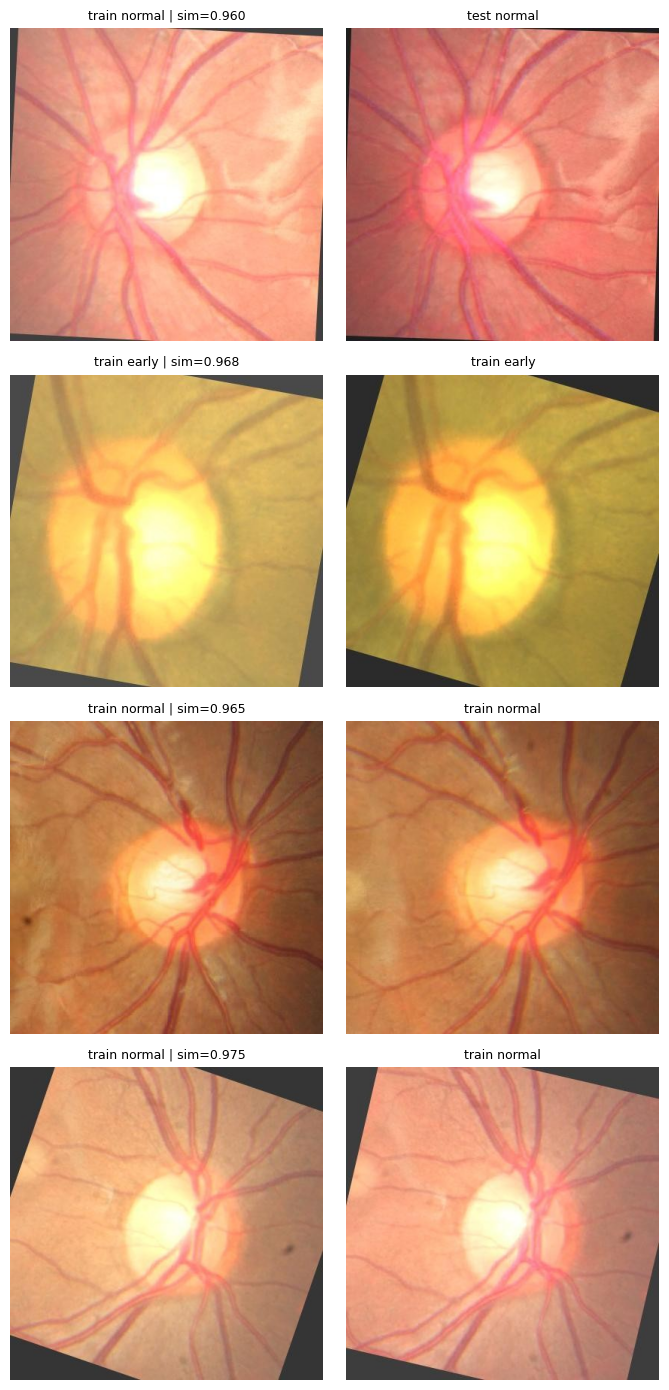

In [7]:
# ============ Deduplicación, nuevo split y prueba de atajo de color ============
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

# --- Pool completo (train + test originales) con sus embeddings ---
pool = pd.concat([tr, te], ignore_index=True)
E = torch.cat([Etr, Ete])
S = (E @ E.T).numpy()
np.fill_diagonal(S, -1)

# --- Sensibilidad al umbral de similitud ---
print("Pares casi idénticos según umbral:")
for t in [0.99, 0.98, 0.97, 0.96]:
    ii, jj = np.where(np.triu(S >= t, 1))
    cruce = sum(pool.split[i] != pool.split[j] for i, j in zip(ii, jj))
    print(f"  sim >= {t}: {len(ii):>4} pares | {cruce:>3} entre train y test")

# --- Grupos de duplicados (md5 igual o sim >= THR) con union-find ---
THR = 0.96
parent = list(range(len(pool)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)

for i, j in zip(*np.where(np.triu(S >= THR, 1))):
    union(i, j)
for _, g in pool.groupby("md5"):
    idx = list(g.index)
    for k in idx[1:]:
        union(idx[0], k)
pool["grupo"] = [find(i) for i in range(len(pool))]

# --- Conflictos de etiqueta: misma imagen con clases distintas ---
nclases = pool.groupby("grupo").clase.nunique()
conflictos = nclases[nclases > 1].index
print(f"\nGrupos con etiquetas contradictorias: {len(conflictos)} (se eliminan)")

# --- Pool limpio: una sola imagen por grupo ---
clean = (pool[~pool.grupo.isin(conflictos)]
         .drop_duplicates("grupo").reset_index(drop=True))
print(f"Imágenes: {len(pool)} -> {len(clean)} tras depurar")
print(clean.clase.value_counts().to_string(), "\n")

# --- Nuevo split estratificado 70/15/15 ---
trv, test = train_test_split(clean, test_size=0.15, stratify=clean.clase, random_state=42)
train, val = train_test_split(trv, test_size=0.1765, stratify=trv.clase, random_state=42)
resumen = pd.concat([train.assign(split="train"), val.assign(split="val"),
                     test.assign(split="test")])
print(resumen.groupby(["split", "clase"]).size().unstack(), "\n")
resumen[["ruta", "clase", "split"]].to_csv("/content/splits_moondream.csv", index=False)

# --- Prueba de atajo: ¿el color medio RGB solo clasifica? ---
feats = ["R", "G", "B"]
clf = LogisticRegression(max_iter=1000).fit(train[feats], train.clase)
pred = clf.predict(test[feats])
orden = ["normal", "early", "advanced"]
print("Solo color medio (RGB) -> 3 clases:")
print(f"  Exactitud: {accuracy_score(test.clase, pred):.3f}  (azar ponderado ≈ 0.50 por la clase normal)")
print(pd.DataFrame(confusion_matrix(test.clase, pred, labels=orden),
                   index=[f"real_{c}" for c in orden],
                   columns=[f"pred_{c}" for c in orden]))
bin_acc = ((pred == "normal") == (test.clase == "normal")).mean()
print(f"  Normal vs resto solo con color: {bin_acc:.3f}")

# --- Pares en la zona gris (0.96 - 0.99) para inspección visual ---
ii, jj = np.where(np.triu((S >= 0.96) & (S < 0.99), 1))
if len(ii):
    sel = np.random.RandomState(0).choice(len(ii), min(4, len(ii)), replace=False)
    fig, ax = plt.subplots(len(sel), 2, figsize=(7, 3.5 * len(sel)), squeeze=False)
    for r, k in enumerate(sel):
        a, b = ii[k], jj[k]
        ax[r, 0].imshow(Image.open(pool.ruta[a])); ax[r, 0].set_title(f"{pool.split[a]} {pool.clase[a]} | sim={S[a, b]:.3f}", fontsize=9)
        ax[r, 1].imshow(Image.open(pool.ruta[b])); ax[r, 1].set_title(f"{pool.split[b]} {pool.clase[b]}", fontsize=9)
        ax[r, 0].axis("off"); ax[r, 1].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No hay pares en la zona 0.96-0.99.")

###Preprocesamiento

Dispositivo: cuda
clase  advanced  early  normal
split                         
test         29     27      59
train       131    127     274
val          29     27      59 

Pesos de clase: {'Sano': 0.647, 'Etapa inicial': 1.396, 'Glaucoma': 1.354}
Batch: (32, 3, 224, 224) | etiquetas: [1, 1, 2, 0, 2, 2, 0, 0]


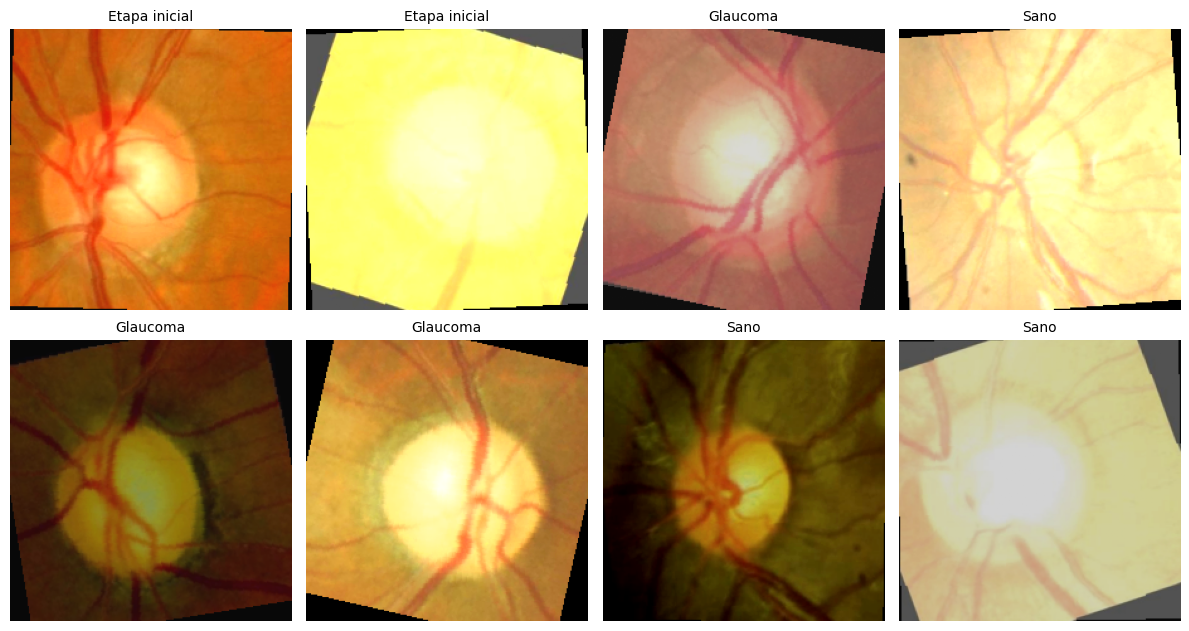

In [8]:
# ============ Datos, preprocesamiento y DataLoaders ============
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt

# --- Reproducibilidad ---
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

# --- Etiquetas: 0 = Sano, 1 = Etapa inicial, 2 = Glaucoma ---
CLASES = ["Sano", "Etapa inicial", "Glaucoma"]
MAPA = {"normal": 0, "early": 1, "advanced": 2}

splits = pd.read_csv("/content/splits_moondream.csv")
splits["y"] = splits.clase.map(MAPA)
print(splits.groupby(["split", "clase"]).size().unstack(), "\n")

# --- Transformaciones ---
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

tf_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),  # mitiga el atajo de color suavizado
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
tf_eval = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# --- Dataset ---
class GlaucomaDS(Dataset):
    def __init__(self, df, tf):
        self.paths = df.ruta.tolist()
        self.y = df.y.tolist()
        self.tf = tf
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.y[i]

df_tr = splits[splits.split == "train"]
df_va = splits[splits.split == "val"]
df_te = splits[splits.split == "test"]

BATCH = 32
g = torch.Generator().manual_seed(SEED)
loader_train = DataLoader(GlaucomaDS(df_tr, tf_train), batch_size=BATCH, shuffle=True,
                          num_workers=2, pin_memory=True, generator=g)
loader_val   = DataLoader(GlaucomaDS(df_va, tf_eval), batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
loader_test  = DataLoader(GlaucomaDS(df_te, tf_eval), batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

# --- Pesos de clase (inverso a la frecuencia en train) ---
conteo = df_tr.y.value_counts().sort_index()
pesos = torch.tensor(conteo.sum() / (len(conteo) * conteo.values), dtype=torch.float32).to(device)
print("Pesos de clase:", {CLASES[i]: round(float(p), 3) for i, p in enumerate(pesos.cpu())})

# --- Verificación visual de un batch de entrenamiento ---
x, y = next(iter(loader_train))
print("Batch:", tuple(x.shape), "| etiquetas:", y[:8].tolist())
mean = torch.tensor(MEAN).view(3, 1, 1); std = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, img, lab in zip(axes.ravel(), x[:8], y[:8]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASES[lab], fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

###Entrenamiento Preliminar


===== ConvNeXt-Tiny =====
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 151MB/s]


  ep1: loss_tr=0.807 loss_val=0.814 F1m=0.415 espec_Sano=0.780
  ep2: loss_tr=0.625 loss_val=0.819 F1m=0.456 espec_Sano=0.814
  ep3: loss_tr=0.514 loss_val=0.677 F1m=0.648 espec_Sano=0.847
  ep4: loss_tr=0.431 loss_val=0.631 F1m=0.653 espec_Sano=0.797
  ep5: loss_tr=0.344 loss_val=0.637 F1m=0.688 espec_Sano=0.780
  ep6: loss_tr=0.293 loss_val=0.659 F1m=0.701 espec_Sano=0.915
  ep7: loss_tr=0.288 loss_val=0.623 F1m=0.676 espec_Sano=0.797

===== ResNet-18 =====
  ep1: loss_tr=0.843 loss_val=0.851 F1m=0.475 espec_Sano=0.797
  ep2: loss_tr=0.605 loss_val=0.773 F1m=0.552 espec_Sano=0.847
  ep3: loss_tr=0.468 loss_val=0.773 F1m=0.577 espec_Sano=0.847
  ep4: loss_tr=0.416 loss_val=0.747 F1m=0.543 espec_Sano=0.847
  ep5: loss_tr=0.322 loss_val=0.765 F1m=0.599 espec_Sano=0.847
  ep6: loss_tr=0.287 loss_val=0.763 F1m=0.577 espec_Sano=0.814
  ep7: loss_tr=0.291 loss_val=0.759 F1m=0.606 espec_Sano=0.814

===== Swin-T =====
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /

100%|██████████| 108M/108M [00:00<00:00, 166MB/s] 


  ep1: loss_tr=0.815 loss_val=0.839 F1m=0.408 espec_Sano=0.881
  ep2: loss_tr=0.687 loss_val=0.814 F1m=0.541 espec_Sano=0.864
  ep3: loss_tr=0.613 loss_val=0.671 F1m=0.646 espec_Sano=0.814
  ep4: loss_tr=0.528 loss_val=1.006 F1m=0.495 espec_Sano=0.864
  ep5: loss_tr=0.532 loss_val=0.767 F1m=0.585 espec_Sano=0.864
  ep6: loss_tr=0.457 loss_val=0.626 F1m=0.679 espec_Sano=0.831
  ep7: loss_tr=0.387 loss_val=0.630 F1m=0.672 espec_Sano=0.780

        Modelo       Espec. Sano Sens. enfermo Recall inicial Recall glaucoma          F1 macro Exactitud Params (M) Min
ConvNeXt-Tiny 0.915 [0.84-0.97]         0.732          0.519           0.621 0.701 [0.60-0.79]     0.748       27.8 1.0
    ResNet-18 0.814 [0.72-0.90]         0.679          0.333           0.655 0.606 [0.51-0.70]     0.661       11.2 0.8
       Swin-T 0.831 [0.73-0.92]         0.821          0.407           0.828 0.679 [0.59-0.76]     0.730       27.5 0.9


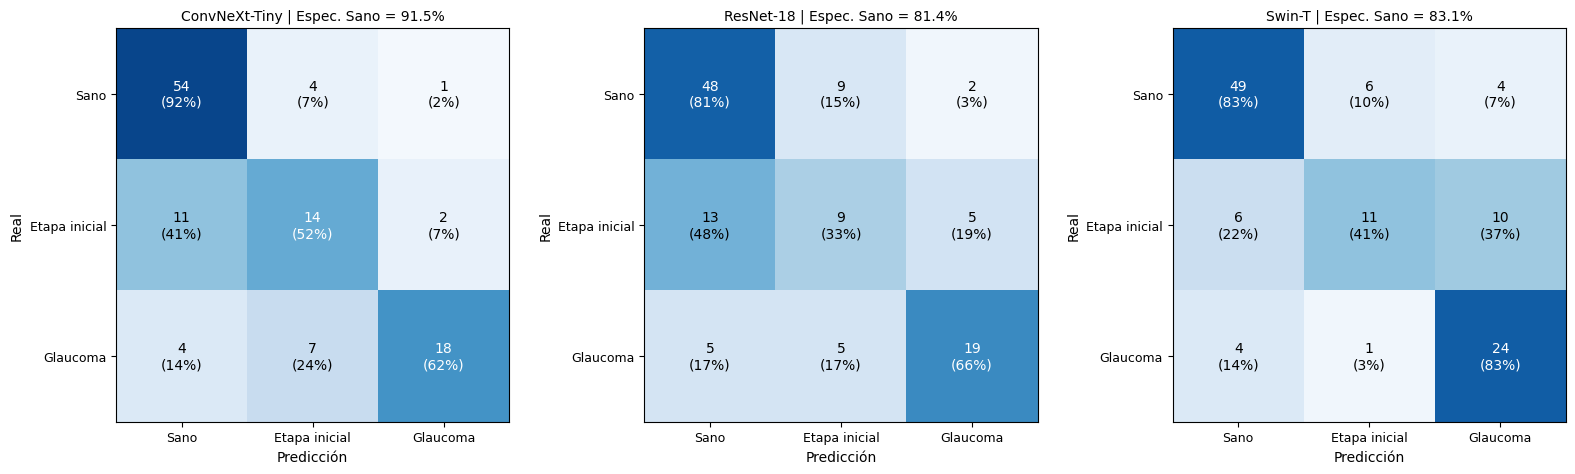

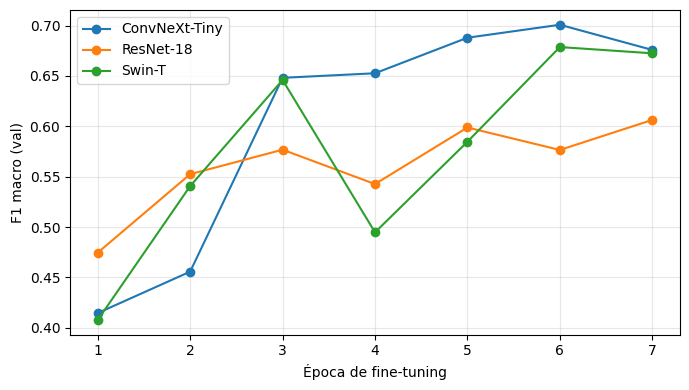

In [9]:
# ============ Benchmark de 3 modelos base (selección con VALIDACIÓN) ============
import time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import confusion_matrix, f1_score
import matplotlib.pyplot as plt

if device == "cpu":
    raise RuntimeError("Cambia el entorno a GPU (T4) antes de ejecutar el benchmark.")

EP_WARMUP, EP_FT = 1, 7
LR_HEAD, LR_FT, WD = 1e-3, 1e-4, 1e-4
USAR_PESOS = False  # sin pesos de clase: los FP son caros

def construir(nombre):
    if nombre == "ResNet-18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, 3); head = m.fc
    elif nombre == "ConvNeXt-Tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, 3); head = m.classifier[2]
    elif nombre == "Swin-T":
        m = models.swin_t(weights=models.Swin_T_Weights.DEFAULT)
        m.head = nn.Linear(m.head.in_features, 3); head = m.head
    return m.to(device), head

def correr_epoca(m, loader, crit, opt=None, scaler=None):
    entrenando = opt is not None
    m.train(entrenando)
    perdida, n, P, Y = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(entrenando):
            with torch.autocast(device_type="cuda"):
                out = m(x); loss = crit(out, y)
            if entrenando:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        perdida += loss.item() * len(y); n += len(y)
        P += out.argmax(1).cpu().tolist(); Y += y.cpu().tolist()
    return perdida / n, np.array(Y), np.array(P)

def metricas(y, p):
    cm = confusion_matrix(y, p, labels=[0, 1, 2])
    fp = cm[0, 1] + cm[0, 2]                         # Sano predicho como enfermo
    return {
        "especificidad_Sano": 1 - fp / cm[0].sum(),
        "sens_enfermo": cm[1:, 1:].sum() / cm[1:].sum(),   # enfermo (inicial o glaucoma) detectado como enfermo
        "recall_inicial": cm[1, 1] / cm[1].sum(),
        "recall_glaucoma": cm[2, 2] / cm[2].sum(),
        "F1_macro": f1_score(y, p, average="macro"),
        "exactitud": np.trace(cm) / cm.sum(),
    }, cm

def bootstrap_ic(y, p, n=1000, seed=0):
    rng = np.random.RandomState(seed); esp, f1 = [], []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        m_, _ = metricas(y[i], p[i]); esp.append(m_["especificidad_Sano"]); f1.append(m_["F1_macro"])
    return np.percentile(esp, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

crit = nn.CrossEntropyLoss(weight=pesos if USAR_PESOS else None)
resultados, historiales = {}, {}

for nombre in ["ConvNeXt-Tiny", "ResNet-18", "Swin-T"]:
    print(f"\n===== {nombre} =====")
    torch.manual_seed(SEED)
    m, head = construir(nombre)
    t0 = time.time()
    scaler = torch.amp.GradScaler("cuda")

    # Fase 1: warmup, backbone congelado
    for p_ in m.parameters(): p_.requires_grad = False
    for p_ in head.parameters(): p_.requires_grad = True
    opt = torch.optim.AdamW(head.parameters(), lr=LR_HEAD, weight_decay=WD)
    for _ in range(EP_WARMUP):
        correr_epoca(m, loader_train, crit, opt, scaler)

    # Fase 2: fine-tuning completo
    for p_ in m.parameters(): p_.requires_grad = True
    opt = torch.optim.AdamW(m.parameters(), lr=LR_FT, weight_decay=WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EP_FT, eta_min=1e-6)

    mejor, mejor_f1, hist = None, -1, []
    for ep in range(1, EP_FT + 1):
        l_tr, _, _ = correr_epoca(m, loader_train, crit, opt, scaler)
        sched.step()
        l_va, yv, pv = correr_epoca(m, loader_val, crit)
        mv, _ = metricas(yv, pv)
        hist.append({"epoca": ep, "loss_train": l_tr, "loss_val": l_va, **mv})
        print(f"  ep{ep}: loss_tr={l_tr:.3f} loss_val={l_va:.3f} F1m={mv['F1_macro']:.3f} espec_Sano={mv['especificidad_Sano']:.3f}")
        if mv["F1_macro"] > mejor_f1:
            mejor_f1, mejor = mv["F1_macro"], copy.deepcopy(m.state_dict())

    m.load_state_dict(mejor)
    _, yv, pv = correr_epoca(m, loader_val, crit)
    mv, cm = metricas(yv, pv)
    ic_esp, ic_f1 = bootstrap_ic(yv, pv)
    resultados[nombre] = {**mv, "cm": cm, "IC_espec": ic_esp, "IC_F1": ic_f1,
                          "parametros_M": sum(p_.numel() for p_ in m.parameters()) / 1e6,
                          "min": (time.time() - t0) / 60}
    historiales[nombre] = pd.DataFrame(hist)
    import os; os.makedirs("/content/modelos", exist_ok=True)
    torch.save(mejor, f"/content/modelos/{nombre}_val.pth")
    del m, opt; torch.cuda.empty_cache()

# --- Tabla comparativa (VALIDACIÓN) ---
filas = []
for n_, r in resultados.items():
    filas.append({"Modelo": n_,
                  "Espec. Sano": f"{r['especificidad_Sano']:.3f} [{r['IC_espec'][0]:.2f}-{r['IC_espec'][1]:.2f}]",
                  "Sens. enfermo": f"{r['sens_enfermo']:.3f}",
                  "Recall inicial": f"{r['recall_inicial']:.3f}",
                  "Recall glaucoma": f"{r['recall_glaucoma']:.3f}",
                  "F1 macro": f"{r['F1_macro']:.3f} [{r['IC_F1'][0]:.2f}-{r['IC_F1'][1]:.2f}]",
                  "Exactitud": f"{r['exactitud']:.3f}",
                  "Params (M)": f"{r['parametros_M']:.1f}",
                  "Min": f"{r['min']:.1f}"})
print("\n", pd.DataFrame(filas).to_string(index=False))

# --- Matrices de confusión (VALIDACIÓN) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (n_, r) in zip(axes, resultados.items()):
    cm = r["cm"]; pct = cm / cm.sum(1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASES, fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASES, fontsize=9)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{n_} | Espec. Sano = {r['especificidad_Sano']:.1%}", fontsize=10)
plt.tight_layout(); plt.show()

# --- Curva de F1 macro en validación por época ---
plt.figure(figsize=(7, 4))
for n_, h in historiales.items():
    plt.plot(h.epoca, h.F1_macro, marker="o", label=n_)
plt.xlabel("Época de fine-tuning"); plt.ylabel("F1 macro (val)"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.show()

###Resumen

,FP (Sano→enfermo),Espec. Sano (%),IC95 espec. (%),Sens. enfermo (%),Recall inicial (%),Recall glaucoma (%),F1 macro,Exactitud (%)
Modelo,,,,,,,,
ConvNeXt-Tiny,5,91.5,84–97,73.2,51.9,62.1,0.701,74.8
Swin-T,10,83.1,73–92,82.1,40.7,82.8,0.679,73.0
ResNet-18,11,81.4,72–90,67.9,33.3,65.5,0.606,66.1


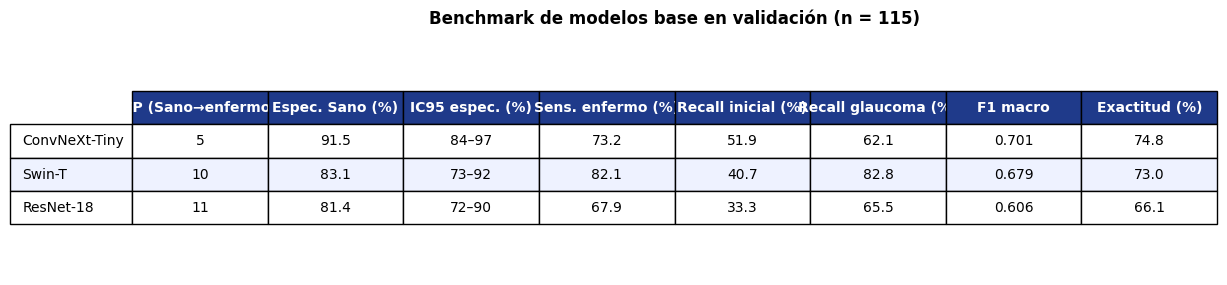

In [10]:
# ============ Tabla comparativa del benchmark (validación) ============
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# --- Construcción de la tabla desde `resultados` ---
filas = []
for nombre, r in resultados.items():
    cm = r["cm"]
    filas.append({
        "Modelo": nombre,
        "FP (Sano→enfermo)": int(cm[0, 1] + cm[0, 2]),
        "Espec. Sano (%)": r["especificidad_Sano"] * 100,
        "IC95 espec. (%)": f"{r['IC_espec'][0]*100:.0f}–{r['IC_espec'][1]*100:.0f}",
        "Sens. enfermo (%)": r["sens_enfermo"] * 100,
        "Recall inicial (%)": r["recall_inicial"] * 100,
        "Recall glaucoma (%)": r["recall_glaucoma"] * 100,
        "F1 macro": r["F1_macro"],
        "Exactitud (%)": r["exactitud"] * 100,
    })
tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 macro", ascending=False)

# --- Versión con estilo para el cuaderno (mejor valor de cada columna en verde) ---
cols_max = ["Espec. Sano (%)", "Sens. enfermo (%)", "Recall inicial (%)",
            "Recall glaucoma (%)", "F1 macro", "Exactitud (%)"]
estilo = (
    tabla.style
    .format({"Espec. Sano (%)": "{:.1f}", "Sens. enfermo (%)": "{:.1f}",
             "Recall inicial (%)": "{:.1f}", "Recall glaucoma (%)": "{:.1f}",
             "F1 macro": "{:.3f}", "Exactitud (%)": "{:.1f}"})
    .highlight_min(subset=["FP (Sano→enfermo)"], color="#c6efce")
    .highlight_max(subset=cols_max, color="#c6efce")
    .set_caption("Benchmark en validación (n = 115): 59 sanos, 27 etapa inicial, 29 glaucoma")
    .set_table_styles([
        {"selector": "th", "props": [("background-color", "#1F3A8A"), ("color", "white"),
                                     ("text-align", "center"), ("padding", "6px")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "6px")]},
        {"selector": "caption", "props": [("font-size", "13px"), ("font-weight", "bold"),
                                          ("padding", "8px"), ("caption-side", "top")]},
    ])
)
display(estilo)

# --- Exportar a CSV ---
tabla.to_csv("/content/benchmark_validacion.csv")

# --- Exportar a imagen PNG (para el informe) ---
texto = tabla.copy().astype(object)
for c in ["Espec. Sano (%)", "Sens. enfermo (%)", "Recall inicial (%)", "Recall glaucoma (%)", "Exactitud (%)"]:
    texto[c] = tabla[c].map("{:.1f}".format)
texto["F1 macro"] = tabla["F1 macro"].map("{:.3f}".format)

fig, ax = plt.subplots(figsize=(14, 1.4 + 0.55 * len(texto)))
ax.axis("off")
tb = ax.table(cellText=texto.values, colLabels=texto.columns, rowLabels=texto.index,
              loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 2.0)
for (i, j), celda in tb.get_celld().items():
    if i == 0:
        celda.set_facecolor("#1F3A8A"); celda.set_text_props(color="white", weight="bold")
    elif i % 2 == 0:
        celda.set_facecolor("#EEF2FF")
ax.set_title("Benchmark de modelos base en validación (n = 115)", fontsize=12, weight="bold", pad=12)
plt.savefig("/content/tabla_benchmark.png", dpi=200, bbox_inches="tight")
plt.show()

###Entrenamiento Definitivo

ep 1: loss_tr=0.851 loss_val=0.760 F1m=0.454 rec_ini=0.000 rec_glau=0.828 score=0.434  <- mejor (F1 + Recall)
ep 2: loss_tr=0.655 loss_val=0.687 F1m=0.582 rec_ini=0.148 rec_glau=1.000 score=0.578  <- mejor (F1 + Recall)
ep 3: loss_tr=0.634 loss_val=0.645 F1m=0.624 rec_ini=0.296 rec_glau=0.931 score=0.619  <- mejor (F1 + Recall)
ep 4: loss_tr=0.493 loss_val=0.583 F1m=0.676 rec_ini=0.370 rec_glau=0.897 score=0.655  <- mejor (F1 + Recall)
ep 5: loss_tr=0.366 loss_val=0.617 F1m=0.685 rec_ini=0.556 rec_glau=0.517 score=0.611
ep 6: loss_tr=0.351 loss_val=0.574 F1m=0.723 rec_ini=0.667 rec_glau=0.828 score=0.735  <- mejor (F1 + Recall)
ep 7: loss_tr=0.250 loss_val=0.568 F1m=0.717 rec_ini=0.667 rec_glau=0.828 score=0.732
ep 8: loss_tr=0.179 loss_val=0.641 F1m=0.728 rec_ini=0.778 rec_glau=0.759 score=0.748  <- mejor (F1 + Recall)
ep 9: loss_tr=0.144 loss_val=0.593 F1m=0.718 rec_ini=0.593 rec_glau=0.655 score=0.671
ep10: loss_tr=0.115 loss_val=0.564 F1m=0.759 rec_ini=0.704 rec_glau=0.724 score=0.

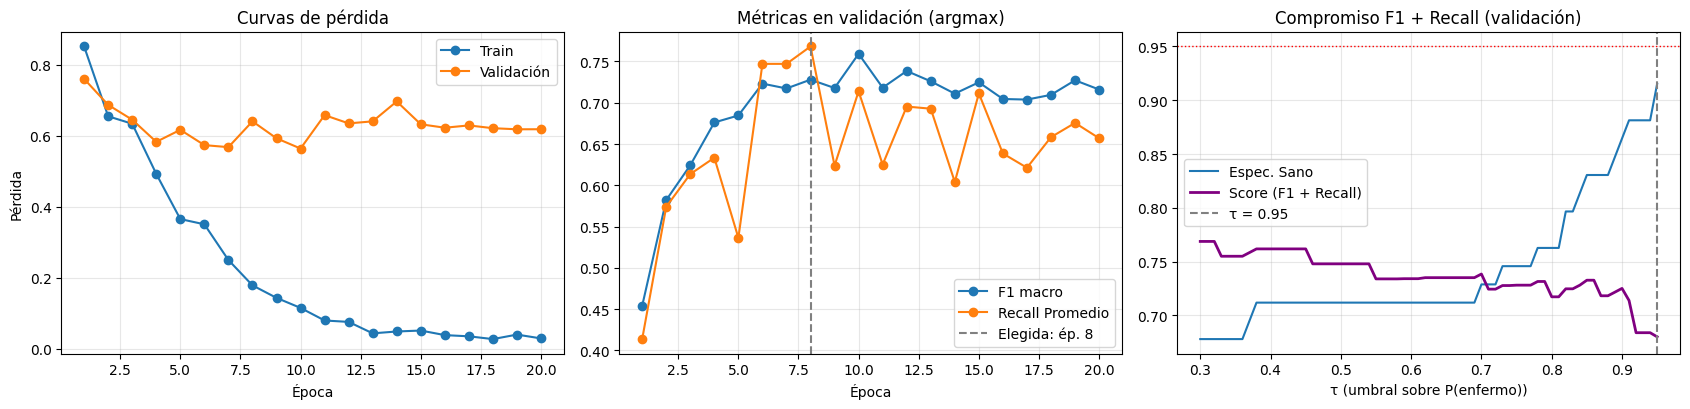

In [11]:
# ============ Entrenamiento final + selección de época + calibración de umbral (F1 + RECALL) ============
import copy, os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

assert device == "cuda", "Activa la GPU (T4) antes de ejecutar."

# --- Configuración ---
EP_WARM, EP_FINAL = 1, 20          # mismos hiperparámetros del benchmark
LR_HEAD, LR_FT, WD = 1e-3, 1e-4, 1e-4
ESPEC_OBJ = 0.95                   # objetivo de especificidad de Sano (validación)

@torch.no_grad()
def evaluar(m, loader):
    m.eval(); P, Y, L = [], [], 0.0
    for x, y in loader:
        x = x.to(device)
        with torch.autocast(device_type="cuda"):
            out = m(x)
        out = out.float()
        P.append(torch.softmax(out, 1).cpu()); Y.append(y)
        L += nn.functional.cross_entropy(out, y.to(device), reduction="sum").item()
    Y = torch.cat(Y).numpy()
    return L / len(Y), Y, torch.cat(P).numpy()

def decidir(P, tau):
    """Predice enfermo solo si P(enfermo) >= tau; entonces elige entre Inicial y Glaucoma."""
    p_enf = 1 - P[:, 0]
    return np.where(p_enf >= tau, 1 + P[:, 1:].argmax(1), 0)

# --- Entrenamiento ---
torch.manual_seed(SEED)
m, head = construir("ConvNeXt-Tiny")
crit_f = nn.CrossEntropyLoss()           # sin pesos de clase
scaler = torch.amp.GradScaler("cuda")
t0 = time.time()

for p_ in m.parameters(): p_.requires_grad = False
for p_ in head.parameters(): p_.requires_grad = True
opt = torch.optim.AdamW(head.parameters(), lr=LR_HEAD, weight_decay=WD)
for _ in range(EP_WARM):
    correr_epoca(m, loader_train, crit_f, opt, scaler)

for p_ in m.parameters(): p_.requires_grad = True
opt = torch.optim.AdamW(m.parameters(), lr=LR_FT, weight_decay=WD)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EP_FINAL, eta_min=1e-6)

hist, mejor_estado, mejor_score, mejor_ep = [], None, -float("inf"), 0
for ep in range(1, EP_FINAL + 1):
    l_tr, _, _ = correr_epoca(m, loader_train, crit_f, opt, scaler)
    sched.step()
    l_va, yv, Pv = evaluar(m, loader_val)
    mv, _ = metricas(yv, Pv.argmax(1))

    # Score combinado: F1 macro + promedio de Recall (inicial y glaucoma)
    recalls_promedio = (mv["recall_inicial"] + mv["recall_glaucoma"]) / 2
    score = 0.5 * mv["F1_macro"] + 0.5 * recalls_promedio

    hist.append({"epoca": ep, "loss_train": l_tr, "loss_val": l_va, "score": score, **mv})
    marca = ""
    if score > mejor_score:
        mejor_score, mejor_ep, marca = score, ep, "  <- mejor (F1 + Recall)"
        mejor_estado = copy.deepcopy(m.state_dict())
    print(f"ep{ep:>2}: loss_tr={l_tr:.3f} loss_val={l_va:.3f} F1m={mv['F1_macro']:.3f} "
          f"rec_ini={mv['recall_inicial']:.3f} rec_glau={mv['recall_glaucoma']:.3f} score={score:.3f}{marca}")
hist = pd.DataFrame(hist)
print(f"\nEntrenamiento: {(time.time() - t0) / 60:.1f} min | mejor época seleccionada: {mejor_ep}")

# --- Mejor época: probabilidades de validación ---
m.load_state_dict(mejor_estado)
_, yv, Pv = evaluar(m, loader_val)

# --- Calibración de umbral optimizando F1 y Recall ---
taus = np.round(np.arange(0.30, 0.96, 0.01), 2)
curva = []
for t in taus:
    m_t, _ = metricas(yv, decidir(Pv, t))
    # Evaluamos balanceando F1 macro y Recall promedio
    rec_prom = (m_t["recall_inicial"] + m_t["recall_glaucoma"]) / 2
    score_t = 0.5 * m_t["F1_macro"] + 0.5 * rec_prom
    curva.append({"tau": t, "score_t": score_t, **m_t})

curva = pd.DataFrame(curva)
ok = curva[curva.especificidad_Sano >= ESPEC_OBJ]
if len(ok):
    # Elegir el τ que maximiza la combinación de F1 + Recall dentro de los que cumplen especificidad mínima
    tau = float(ok.loc[ok.score_t.idxmax()].tau)
else:
    mx = curva.especificidad_Sano.max()
    tau = float(curva[curva.especificidad_Sano == mx].sort_values("score_t").iloc[-1].tau)
    print(f"AVISO: ningún τ alcanza espec. {ESPEC_OBJ:.0%} en validación; se usa el de mayor especificidad ({mx:.1%}).")

m_arg, cm_arg = metricas(yv, Pv.argmax(1))
m_tau, cm_tau = metricas(yv, decidir(Pv, tau))
print(f"\nτ elegido = {tau:.2f}")
print(pd.DataFrame({"Argmax": m_arg, f"τ = {tau:.2f}": m_tau}).T.round(3).to_string())
print("\nMatriz de confusión en validación con τ (filas = real, columnas = predicción):")
print(pd.DataFrame(cm_tau, index=CLASES, columns=CLASES))

# --- Gráficas de validación ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(hist.epoca, hist.loss_train, marker="o", label="Train")
ax[0].plot(hist.epoca, hist.loss_val, marker="o", label="Validación")
ax[0].set(xlabel="Época", ylabel="Pérdida", title="Curvas de pérdida"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(hist.epoca, hist.F1_macro, marker="o", label="F1 macro")
ax[1].plot(hist.epoca, (hist.recall_inicial + hist.recall_glaucoma)/2, marker="o", label="Recall Promedio")
ax[1].axvline(mejor_ep, color="gray", ls="--", label=f"Elegida: ép. {mejor_ep}")
ax[1].set(xlabel="Época", title="Métricas en validación (argmax)"); ax[1].legend(); ax[1].grid(alpha=.3)

ax[2].plot(curva.tau, curva.especificidad_Sano, label="Espec. Sano")
ax[2].plot(curva.tau, curva.score_t, label="Score (F1 + Recall)", color="purple", lw=2)
ax[2].axvline(tau, color="gray", ls="--", label=f"τ = {tau:.2f}")
ax[2].axhline(ESPEC_OBJ, color="red", ls=":", lw=1)
ax[2].set(xlabel="τ (umbral sobre P(enfermo))", title="Compromiso F1 + Recall (validación)")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

os.makedirs("/content/modelos", exist_ok=True)
torch.save({"state_dict": mejor_estado, "tau": tau, "epoca": mejor_ep, "clases": CLASES},
           "/content/modelos/convnext_tiny_final.pth")

###Evaluación

TEST (n = 115) — IC 95 % por bootstrap (2000 remuestreos)

                         Métrica              Argmax     Umbral τ = 0.95
           Especificidad de Sano 0.763 [0.654–0.863] 0.932 [0.862–0.984]
Sensibilidad (enfermo detectado) 0.982 [0.941–1.000] 0.804 [0.694–0.904]
            Recall Etapa inicial 0.704 [0.528–0.867] 0.519 [0.324–0.710]
                 Recall Glaucoma 0.793 [0.647–0.936] 0.690 [0.520–0.857]
                        F1 macro 0.733 [0.650–0.812] 0.722 [0.626–0.807]
                       Exactitud 0.757 [0.678–0.835] 0.774 [0.696–0.852]

Falsos positivos y negativos críticos:
  Argmax: FP = 14 de 59 sanos (→ Etapa inicial: 8, → Glaucoma: 6) | enfermos clasificados como Sano: 1 de 56
  Umbral τ = 0.95: FP = 4 de 59 sanos (→ Etapa inicial: 2, → Glaucoma: 2) | enfermos clasificados como Sano: 11 de 56


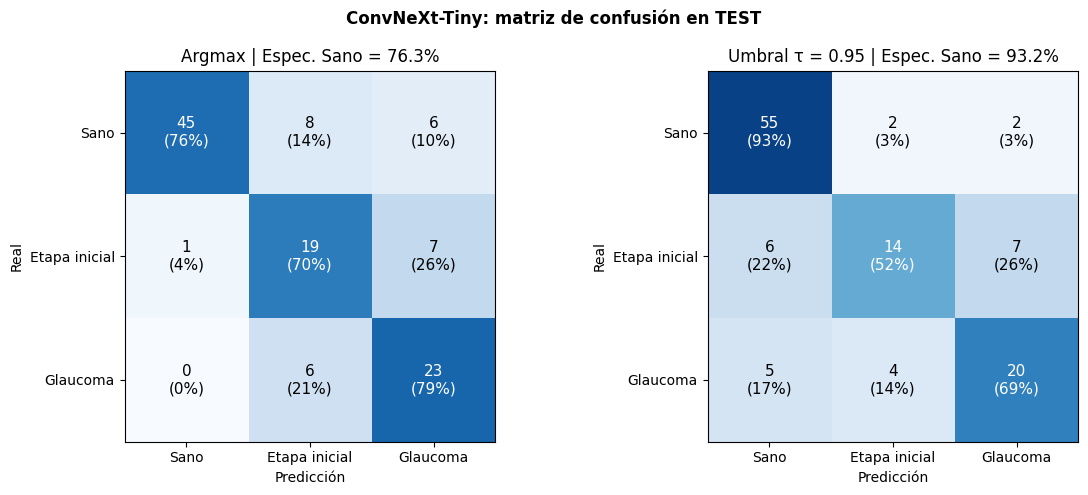


Guardado: /content/modelos/convnext_tiny_final.pth y resultados_test.json


In [12]:
# ============ Evaluación ÚNICA en TEST (matriz de confusión + IC bootstrap) ============
import json

N_BOOT = 2000
NOMBRES = {
    "especificidad_Sano": "Especificidad de Sano",
    "sens_enfermo": "Sensibilidad (enfermo detectado)",
    "recall_inicial": "Recall Etapa inicial",
    "recall_glaucoma": "Recall Glaucoma",
    "F1_macro": "F1 macro",
    "exactitud": "Exactitud",
}

def bootstrap_todas(y, p, n=N_BOOT, seed=0):
    rng = np.random.RandomState(seed)
    acc = {k: [] for k in metricas(y, p)[0]}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        mm, _ = metricas(y[i], p[i])
        for k, v in mm.items():
            acc[k].append(v)
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in acc.items()}

# --- Predicciones en test (modelo de la mejor época, con los pesos ya cargados) ---
m.load_state_dict(mejor_estado)
_, yt, Pt = evaluar(m, loader_test)
pred_arg, pred_tau = Pt.argmax(1), decidir(Pt, tau)
res = {}
for nombre, pred in [("Argmax", pred_arg), (f"Umbral τ = {tau:.2f}", pred_tau)]:
    mm, cm = metricas(yt, pred)
    res[nombre] = {"m": mm, "cm": cm, "ic": bootstrap_todas(yt, pred)}

# --- Tabla con IC 95 % ---
filas = []
for k, nom in NOMBRES.items():
    fila = {"Métrica": nom}
    for nombre, r in res.items():
        v, (lo, hi) = r["m"][k], r["ic"][k]
        fila[nombre] = f"{v:.3f} [{lo:.3f}–{hi:.3f}]"
    filas.append(fila)
print(f"TEST (n = {len(yt)}) — IC 95 % por bootstrap ({N_BOOT} remuestreos)\n")
print(pd.DataFrame(filas).to_string(index=False))

# --- Análisis de falsos positivos (Sano predicho como enfermo) ---
print("\nFalsos positivos y negativos críticos:")
for nombre, r in res.items():
    cm = r["cm"]
    print(f"  {nombre}: FP = {cm[0,1] + cm[0,2]} de {cm[0].sum()} sanos "
          f"(→ Etapa inicial: {cm[0,1]}, → Glaucoma: {cm[0,2]}) | "
          f"enfermos clasificados como Sano: {cm[1,0] + cm[2,0]} de {cm[1:].sum()}")

# --- Matrices de confusión ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, r) in zip(axes, res.items()):
    cm = r["cm"]; pct = cm / cm.sum(1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=11)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASES)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASES)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{nombre} | Espec. Sano = {r['m']['especificidad_Sano']:.1%}")
plt.suptitle("ConvNeXt-Tiny: matriz de confusión en TEST", fontweight="bold")
plt.tight_layout(); plt.show()

# --- Guardar resultados ---
salida = {"tau": tau, "epoca": mejor_ep, "n_test": int(len(yt)),
          "resultados": {n: {"metricas": r["m"], "cm": r["cm"].tolist(),
                             "ic95": {k: v.tolist() for k, v in r["ic"].items()}} for n, r in res.items()}}
with open("/content/modelos/resultados_test.json", "w") as f:
    json.dump(salida, f, indent=2, default=float)
print("\nGuardado: /content/modelos/convnext_tiny_final.pth y resultados_test.json")

###Resumen final

,Argmax,Umbral τ = 0.95
Métrica,,
Especificidad de Sano,76.3 % [65.4–86.3],93.2 % [86.2–98.4]
Sensibilidad (enfermo detectado),98.2 % [94.1–100.0],80.4 % [69.4–90.4]
Recall Etapa inicial,70.4 % [52.8–86.7],51.9 % [32.4–71.0]
Recall Glaucoma,79.3 % [64.7–93.6],69.0 % [52.0–85.7]
F1 macro,0.733 [0.650–0.812],0.722 [0.626–0.807]
Exactitud,75.7 % [67.8–83.5],77.4 % [69.6–85.2]


,Argmax,Umbral τ = 0.95
Concepto,,
Sanos clasificados como Sano (VN),45 / 59 (76.3 %),55 / 59 (93.2 %)
Falsos positivos totales (Sano → enfermo),14 / 59 (23.7 %),4 / 59 (6.8 %)
↳ Sano → Etapa inicial,8 / 59 (13.6 %),2 / 59 (3.4 %)
↳ Sano → Glaucoma,6 / 59 (10.2 %),2 / 59 (3.4 %)
Enfermos clasificados como Sano (FN críticos),1 / 56 (1.8 %),11 / 56 (19.6 %)
↳ Etapa inicial → Sano,1 / 27 (3.7 %),6 / 27 (22.2 %)
↳ Glaucoma → Sano,0 / 29 (0.0 %),5 / 29 (17.2 %)
Confusión entre enfermedades (Inicial ↔ Glaucoma),13 / 56 (23.2 %),11 / 56 (19.6 %)


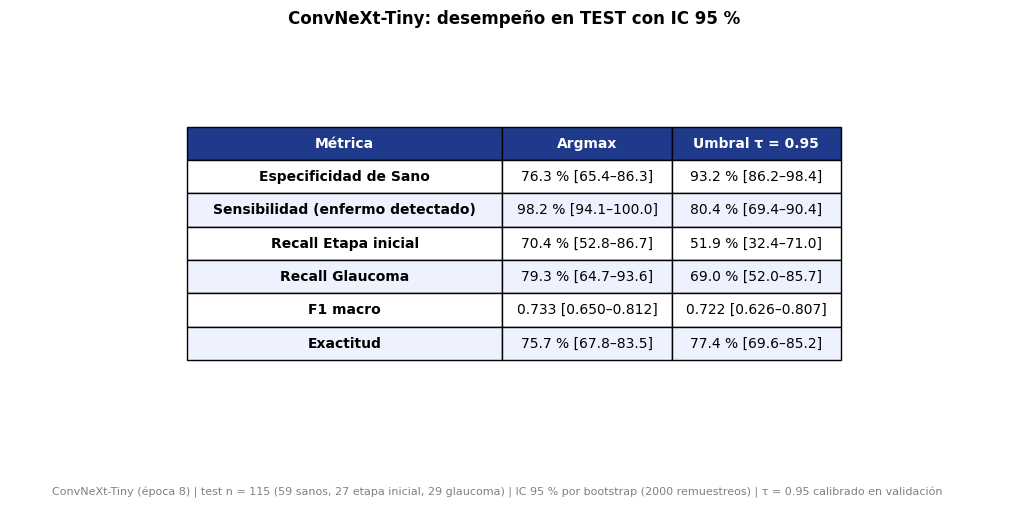

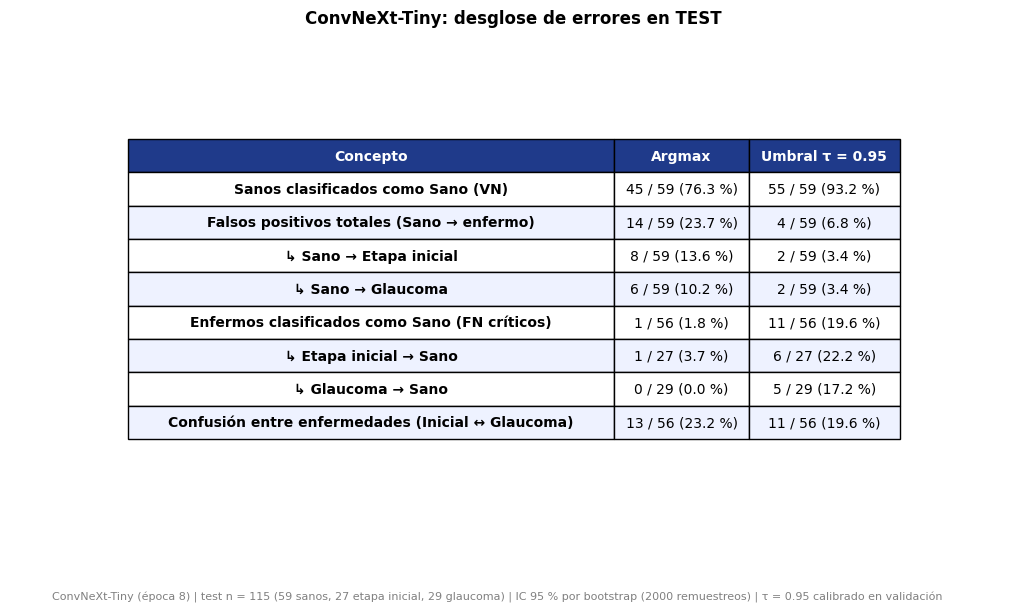

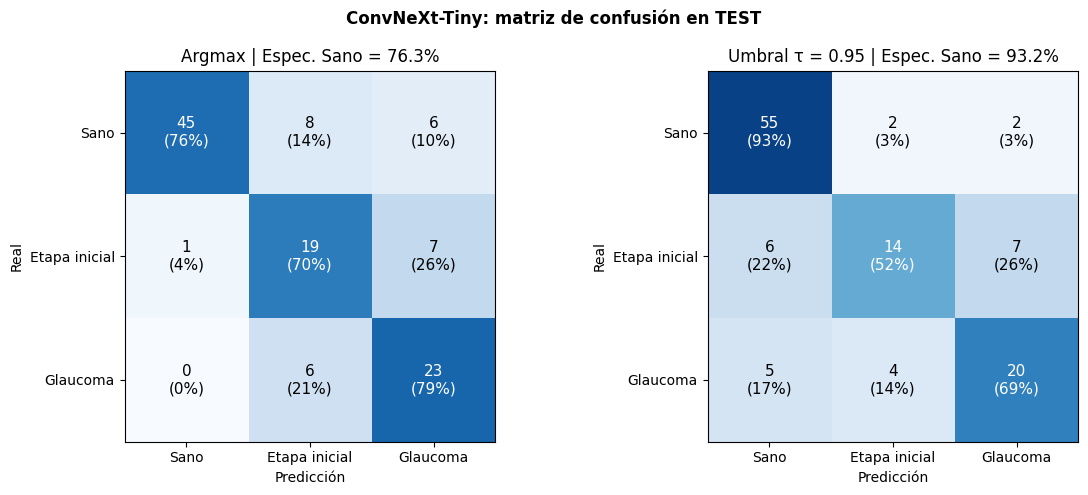

Archivos en /content/resultados: ['matriz_confusion_test.png', 'tabla_test_errores.csv', 'tabla_test_errores.png', 'tabla_test_metricas.csv', 'tabla_test_metricas.png']


In [13]:
# ============ Tablas finales de TEST ============
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.makedirs("/content/resultados", exist_ok=True)
modos = list(res.keys())                                   # ["Argmax", "Umbral τ = 0.77"]
n_test = len(yt)
n_sano, n_ini, n_glau = [int((yt == k).sum()) for k in range(3)]
nota = (f"ConvNeXt-Tiny (época {mejor_ep}) | test n = {n_test} ({n_sano} sanos, {n_ini} etapa inicial, "
        f"{n_glau} glaucoma) | IC 95 % por bootstrap ({N_BOOT} remuestreos) | τ = {tau:.2f} calibrado en validación")

ESTILOS = [
    {"selector": "th", "props": [("background-color", "#1F3A8A"), ("color", "white"),
                                 ("text-align", "center"), ("padding", "6px")]},
    {"selector": "td", "props": [("text-align", "center"), ("padding", "6px")]},
    {"selector": "caption", "props": [("font-size", "13px"), ("font-weight", "bold"),
                                      ("padding", "8px"), ("caption-side", "top")]},
]

# ---------------- TABLA 1: métricas con IC 95 % ----------------
def fmt(k, v, lo, hi):
    if k == "F1_macro":
        return f"{v:.3f} [{lo:.3f}–{hi:.3f}]"
    return f"{v * 100:.1f} % [{lo * 100:.1f}–{hi * 100:.1f}]"

filas, mejores = [], []
for k, nom in NOMBRES.items():
    fila, vals = {"Métrica": nom}, []
    for modo in modos:
        v = res[modo]["m"][k]; lo, hi = res[modo]["ic"][k]
        fila[modo] = fmt(k, v, lo, hi); vals.append(v)
    filas.append(fila)
    mejores.append(None if np.isclose(vals[0], vals[1]) else int(np.argmax(vals)))
t1 = pd.DataFrame(filas).set_index("Métrica")

def resaltar(df):
    css = pd.DataFrame("", index=df.index, columns=df.columns)
    for i, b in enumerate(mejores):
        if b is not None:
            css.iloc[i, b] = "background-color: #c6efce; font-weight: bold"
    return css

display(t1.style.apply(resaltar, axis=None)
        .set_caption("Desempeño en TEST (verde = mayor valor puntual, no implica diferencia significativa)")
        .set_table_styles(ESTILOS))

# ---------------- TABLA 2: desglose de errores ----------------
def c(x, tot):
    return f"{int(x)} / {int(tot)} ({x / tot * 100:.1f} %)"

def fila2(nombre, f):
    return {"Concepto": nombre, **{modo: f(res[modo]["cm"]) for modo in modos}}

t2 = pd.DataFrame([
    fila2("Sanos clasificados como Sano (VN)",          lambda cm: c(cm[0, 0], cm[0].sum())),
    fila2("Falsos positivos totales (Sano → enfermo)",  lambda cm: c(cm[0, 1] + cm[0, 2], cm[0].sum())),
    fila2("↳ Sano → Etapa inicial",                     lambda cm: c(cm[0, 1], cm[0].sum())),
    fila2("↳ Sano → Glaucoma",                          lambda cm: c(cm[0, 2], cm[0].sum())),
    fila2("Enfermos clasificados como Sano (FN críticos)", lambda cm: c(cm[1, 0] + cm[2, 0], cm[1:].sum())),
    fila2("↳ Etapa inicial → Sano",                     lambda cm: c(cm[1, 0], cm[1].sum())),
    fila2("↳ Glaucoma → Sano",                          lambda cm: c(cm[2, 0], cm[2].sum())),
    fila2("Confusión entre enfermedades (Inicial ↔ Glaucoma)", lambda cm: c(cm[1, 2] + cm[2, 1], cm[1:].sum())),
]).set_index("Concepto")

display(t2.style.set_caption("Desglose de errores en TEST").set_table_styles(ESTILOS))

# ---------------- Exportar CSV ----------------
t1.to_csv("/content/resultados/tabla_test_metricas.csv", encoding="utf-8-sig")
t2.to_csv("/content/resultados/tabla_test_errores.csv", encoding="utf-8-sig")

# ---------------- Exportar PNG ----------------
def tabla_png(df, titulo, ruta, ancho=13):
    d = df.reset_index()
    fig, ax = plt.subplots(figsize=(ancho, 1.6 + 0.6 * len(d)))
    ax.axis("off")
    tb = ax.table(cellText=d.values, colLabels=d.columns, loc="center", cellLoc="center")
    tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 2.0)
    tb.auto_set_column_width(list(range(len(d.columns))))
    for (i, j), celda in tb.get_celld().items():
        if i == 0:
            celda.set_facecolor("#1F3A8A"); celda.set_text_props(color="white", weight="bold")
        elif i % 2 == 0:
            celda.set_facecolor("#EEF2FF")
        if j == 0 and i > 0:
            celda.set_text_props(weight="bold")
    ax.set_title(titulo, fontsize=12, weight="bold", pad=14)
    fig.text(0.5, 0.01, nota, ha="center", fontsize=8, color="gray")
    plt.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()

tabla_png(t1, "ConvNeXt-Tiny: desempeño en TEST con IC 95 %", "/content/resultados/tabla_test_metricas.png")
tabla_png(t2, "ConvNeXt-Tiny: desglose de errores en TEST", "/content/resultados/tabla_test_errores.png")

# ---------------- Matrices de confusión (alta resolución) ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (modo, r) in zip(axes, res.items()):
    cm = r["cm"]; pct = cm / cm.sum(1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=11)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASES)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASES)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{modo} | Espec. Sano = {r['m']['especificidad_Sano']:.1%}")
plt.suptitle("ConvNeXt-Tiny: matriz de confusión en TEST", fontweight="bold")
plt.tight_layout()
plt.savefig("/content/resultados/matriz_confusion_test.png", dpi=200, bbox_inches="tight")
plt.show()

print("Archivos en /content/resultados:", sorted(os.listdir("/content/resultados")))
# Para no perderlos al reiniciar (con Drive montado):
# !cp -r /content/resultados /content/drive/MyDrive/glaucoma/

##Experimento datos Google

###Descarga de Datos

In [15]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import hashlib, shutil

# --- CONFIGURACIÓN ---
NOMBRE_CARPETA = "Dataset Glaucoma"   # nombre de la carpeta (o del acceso directo) en Mi unidad
RAW_DIR  = Path("/content/drive/MyDrive") / NOMBRE_CARPETA
DATA_DIR = Path("/content/drive/MyDrive") / f"{NOMBRE_CARPETA}_limpio"   # en Drive para que no se pierda al reiniciar Colab

MIN_LADO   = 128
UMBRAL_DUP = 10
EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif", ".tif", ".tiff"}
# ---------------------

if not RAW_DIR.exists():
    print("No encuentro", RAW_DIR, "\nCarpetas disponibles en Mi unidad:")
    print(sorted(p.name for p in Path("/content/drive/MyDrive").iterdir() if p.is_dir()))
    raise FileNotFoundError("Ajusta NOMBRE_CARPETA")

POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def dhash(img, n=16):
    g = ImageOps.exif_transpose(img).convert("L").resize((n + 1, n), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())   # 256 bits -> 32 bytes

def limpiar(raw_dir, out_dir, min_lado, umbral):
    if out_dir.exists():
        shutil.rmtree(out_dir)
    out_dir.mkdir(parents=True)

    stats = dict(leidas=0, corruptas=0, pequenas=0, dup_exacto=0, dup_similar=0, guardadas=0)
    md5s, hashes, manifiesto = set(), [], []

    archivos = sorted(p for p in raw_dir.iterdir()
                      if p.is_file() and p.suffix.lower() in EXTENSIONES)
    for p in archivos:
        stats["leidas"] += 1
        try:
            with Image.open(p) as im:
                im.load()
                im = ImageOps.exif_transpose(im).convert("RGB")
        except Exception:
            stats["corruptas"] += 1; continue
        if min(im.size) < min_lado:
            stats["pequenas"] += 1; continue

        m = hashlib.md5(im.tobytes()).hexdigest()
        if m in md5s:
            stats["dup_exacto"] += 1; continue

        h = dhash(im)
        if hashes:
            dist = POPCOUNT[np.bitwise_xor(np.stack(hashes), h)].sum(1)
            if (dist <= umbral).any():
                stats["dup_similar"] += 1; continue

        md5s.add(m); hashes.append(h)
        ruta = out_dir / f"{len(manifiesto):05d}.jpg"
        im.save(ruta, quality=95)
        manifiesto.append((ruta.name, p.name))

    stats["guardadas"] = len(manifiesto)
    pd.DataFrame(manifiesto, columns=["archivo", "origen"]).to_csv(out_dir / "manifiesto.csv", index=False)
    return stats

stats = limpiar(RAW_DIR, DATA_DIR, MIN_LADO, UMBRAL_DUP)
pd.Series(stats).to_frame("cantidad")

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


,cantidad
leidas,1145
corruptas,1
pequenas,555
dup_exacto,0
dup_similar,1
guardadas,588


###Vista previa

Imágenes limpias: 588


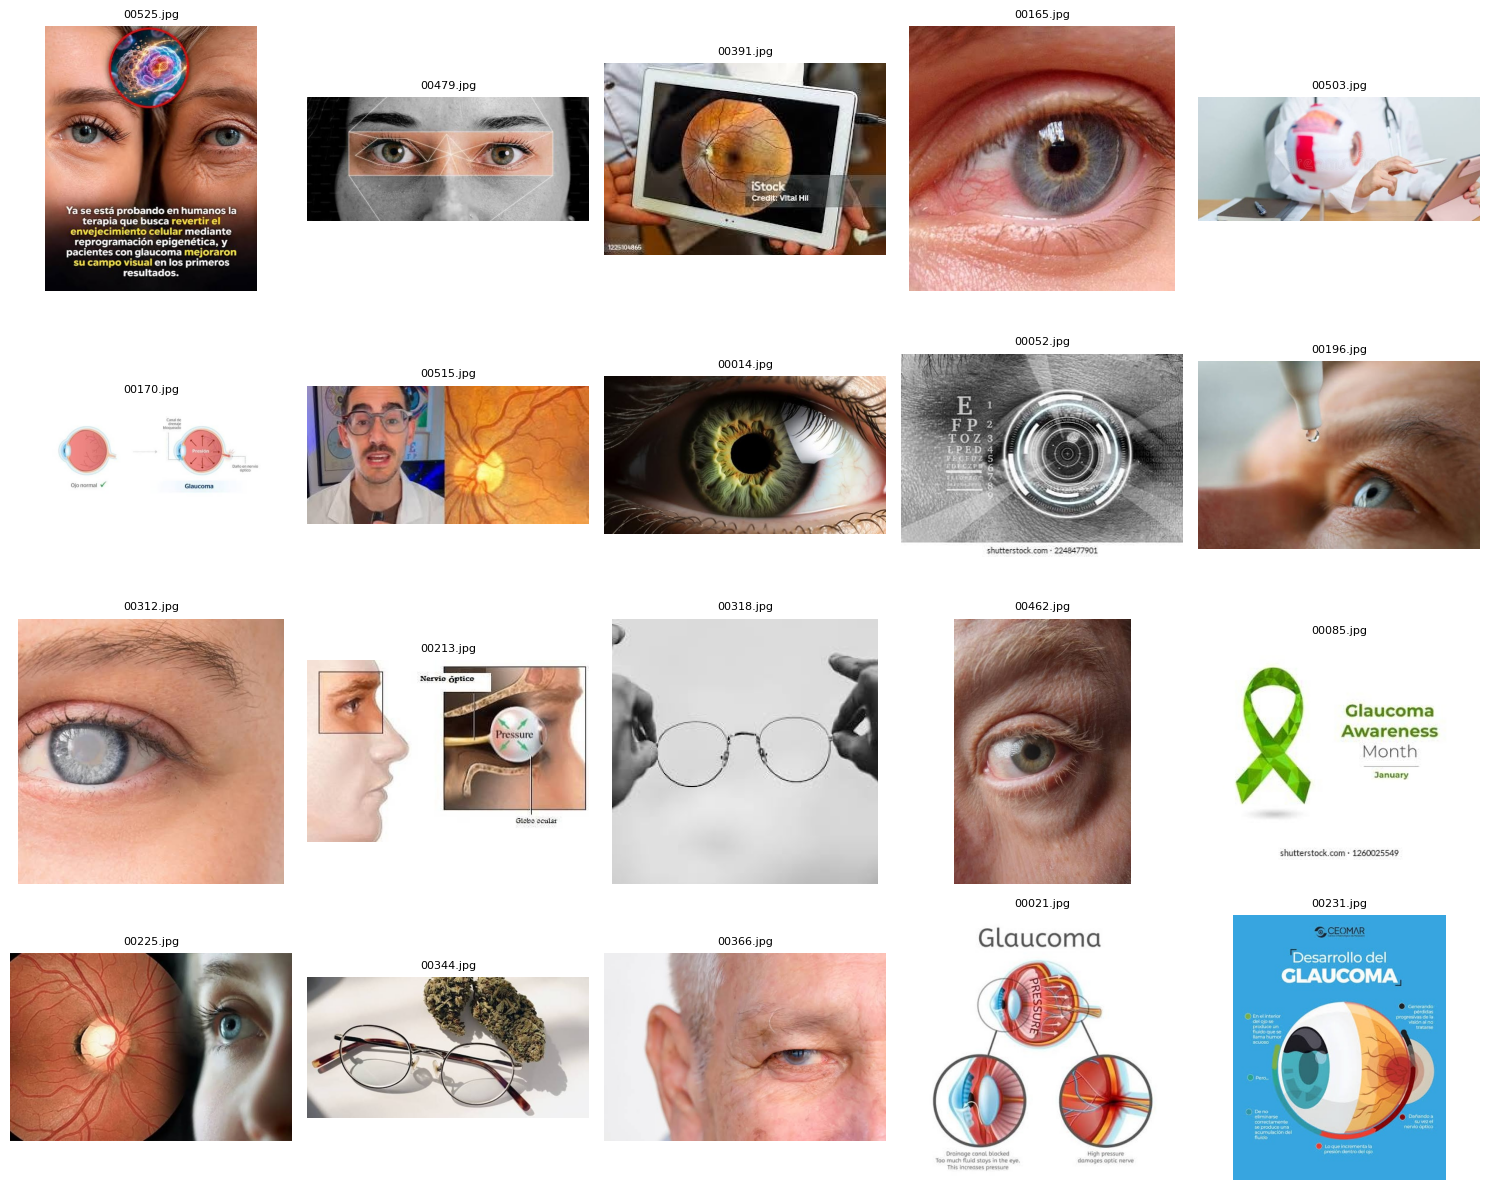

In [16]:
import matplotlib.pyplot as plt

manifiesto = pd.read_csv(DATA_DIR / "manifiesto.csv")
print(f"Imágenes limpias: {len(manifiesto)}")
if "carpeta" in manifiesto.columns:
    print(manifiesto.carpeta.value_counts().to_string())

muestra = manifiesto.sample(min(20, len(manifiesto)), random_state=0)
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (_, fila) in zip(axes.ravel(), muestra.iterrows()):
    ax.imshow(Image.open(DATA_DIR / fila.archivo))
    ax.set_title(fila.archivo, fontsize=8); ax.axis("off")
for ax in axes.ravel()[len(muestra):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Modelo ganador vs imagenes de google

Imágenes a clasificar: 588 | τ del modelo = 0.95

Clase asignada a las imágenes de Google:
               Argmax  τ = 0.95
Sano              413       586
Etapa inicial      74         0
Glaucoma          101         2

Confianza máxima (argmax) en imágenes de Google:
  mediana = 0.554 | ≥ 0.80: 11.7% | ≥ 0.90: 4.4%
Confianza máxima en validación (retinografías reales de Moondream):
  mediana = 0.869 | ≥ 0.80: 56.5% | ≥ 0.90: 45.2%

Con τ, el modelo marca como ENFERMA el 0.3% de las imágenes de Google (casi todas no son retinografías: serían falsas alarmas en un sistema real).


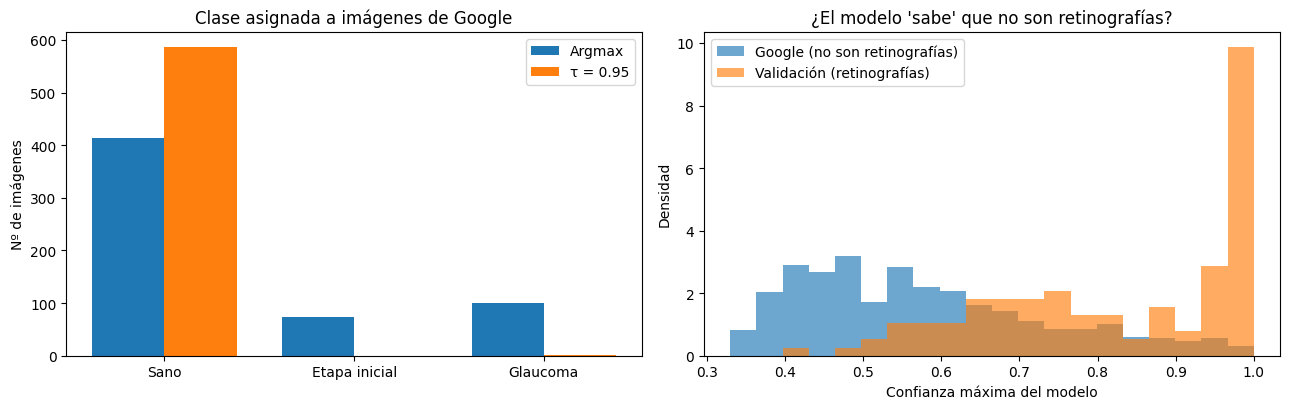

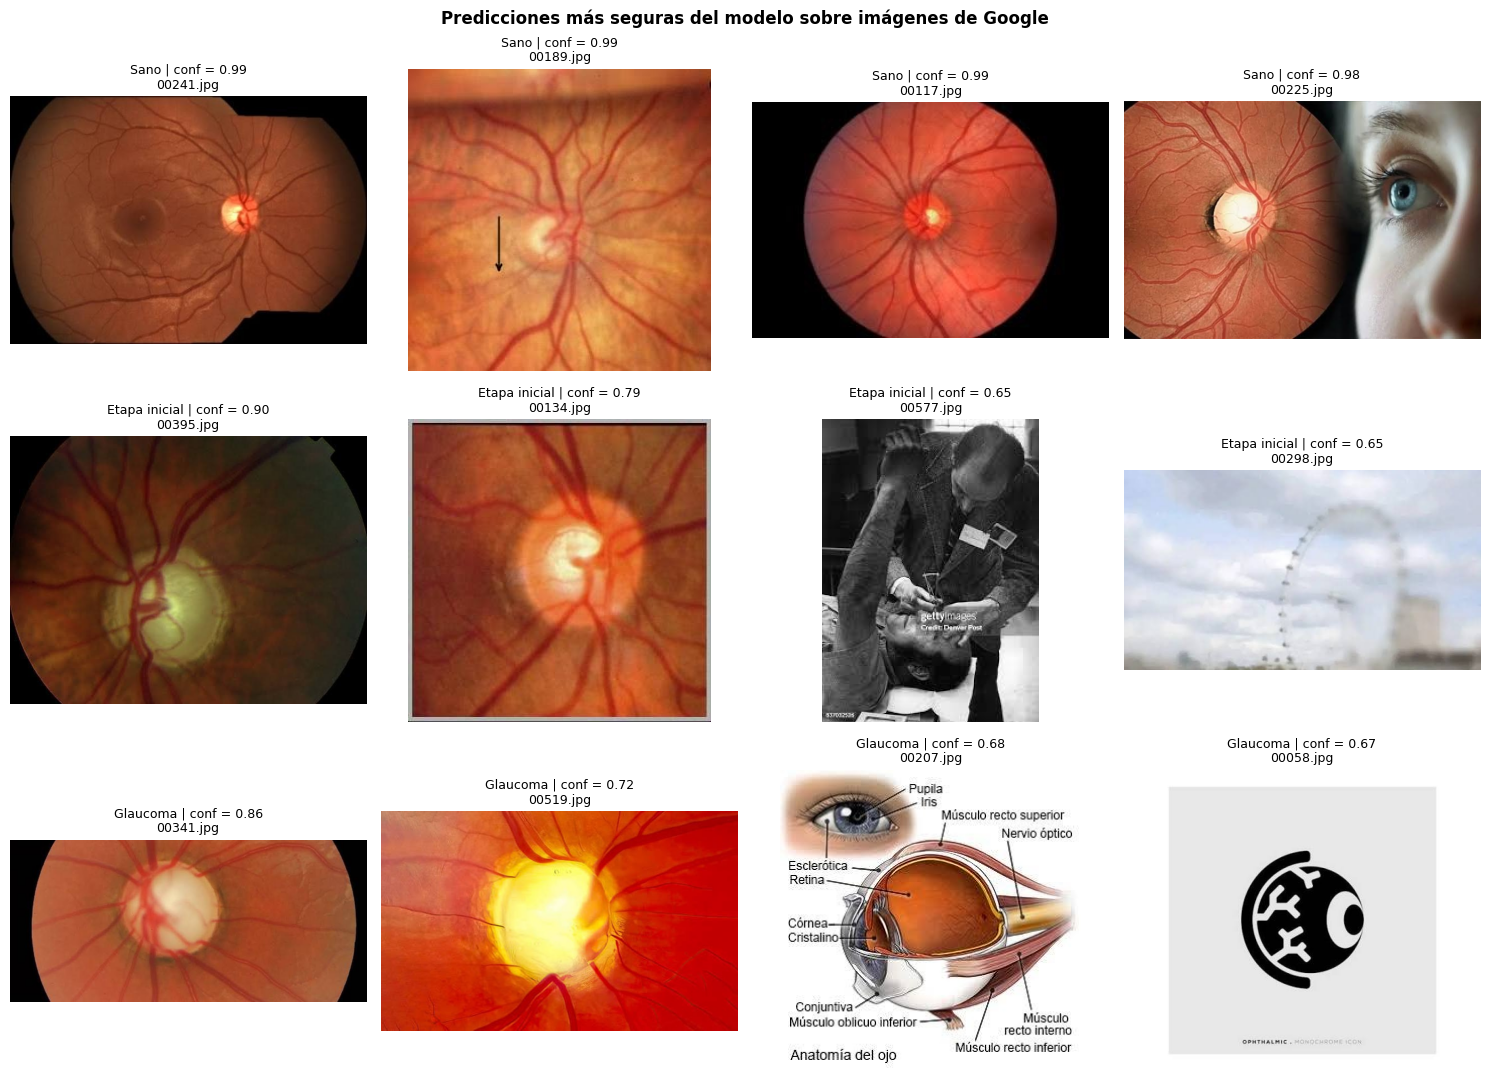

In [17]:
# ============ Modelo ganador frente a imágenes de Google (paso 1) ============
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

WEB_DIR = Path("/content/drive/MyDrive") / f"{NOMBRE_CARPETA}_limpio"
SAL_DIR = Path("/content/drive/MyDrive/glaucoma_experimento_web")
SAL_DIR.mkdir(exist_ok=True)

manifiesto = pd.read_csv(WEB_DIR / "manifiesto.csv")
rutas = [WEB_DIR / a for a in manifiesto.archivo]
print(f"Imágenes a clasificar: {len(rutas)} | τ del modelo = {tau:.2f}")

class WebDS(Dataset):
    def __init__(self, rutas): self.rutas = rutas
    def __len__(self): return len(self.rutas)
    def __getitem__(self, i):
        return tf_eval(Image.open(self.rutas[i]).convert("RGB")), i

@torch.no_grad()
def probs_web(modelo, rutas, bs=32):
    modelo.eval(); P = []
    for x, _ in DataLoader(WebDS(rutas), batch_size=bs, num_workers=2):
        with torch.autocast(device_type="cuda"):
            out = modelo(x.to(device))
        P.append(torch.softmax(out.float(), 1).cpu())
    return torch.cat(P).numpy()

Pw = probs_web(m, rutas)

# --- Tabla de predicciones ---
manifiesto["p_sano"], manifiesto["p_inicial"], manifiesto["p_glaucoma"] = Pw.T
manifiesto["conf"] = Pw.max(1)
manifiesto["pred_argmax"] = [CLASES[i] for i in Pw.argmax(1)]
manifiesto["pred_tau"] = [CLASES[i] for i in decidir(Pw, tau)]
manifiesto.to_csv(SAL_DIR / "pseudoetiquetas_web.csv", index=False)

# --- Resumen numérico ---
resumen = pd.DataFrame({
    "Argmax": manifiesto.pred_argmax.value_counts(),
    f"τ = {tau:.2f}": manifiesto.pred_tau.value_counts(),
}).reindex(CLASES).fillna(0).astype(int)
print("\nClase asignada a las imágenes de Google:")
print(resumen.to_string())

n = len(manifiesto)
print(f"\nConfianza máxima (argmax) en imágenes de Google:")
print(f"  mediana = {manifiesto.conf.median():.3f} | ≥ 0.80: {(manifiesto.conf >= 0.80).mean():.1%} | ≥ 0.90: {(manifiesto.conf >= 0.90).mean():.1%}")
if "Pv" in globals():
    cv = Pv.max(1)
    print("Confianza máxima en validación (retinografías reales de Moondream):")
    print(f"  mediana = {np.median(cv):.3f} | ≥ 0.80: {(cv >= 0.80).mean():.1%} | ≥ 0.90: {(cv >= 0.90).mean():.1%}")

enfermas = (manifiesto.pred_tau != "Sano").mean()
print(f"\nCon τ, el modelo marca como ENFERMA el {enfermas:.1%} de las imágenes de Google "
      "(casi todas no son retinografías: serían falsas alarmas en un sistema real).")

# --- Gráficas: clases asignadas y confianza ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(3); w = 0.38
ax[0].bar(x - w / 2, resumen["Argmax"], w, label="Argmax")
ax[0].bar(x + w / 2, resumen[f"τ = {tau:.2f}"], w, label=f"τ = {tau:.2f}")
ax[0].set_xticks(x); ax[0].set_xticklabels(CLASES)
ax[0].set(ylabel="Nº de imágenes", title="Clase asignada a imágenes de Google"); ax[0].legend()

bins = np.linspace(0.33, 1.0, 21)
ax[1].hist(manifiesto.conf, bins=bins, alpha=.65, density=True, label="Google (no son retinografías)")
if "Pv" in globals():
    ax[1].hist(Pv.max(1), bins=bins, alpha=.65, density=True, label="Validación (retinografías)")
ax[1].set(xlabel="Confianza máxima del modelo", ylabel="Densidad",
          title="¿El modelo 'sabe' que no son retinografías?"); ax[1].legend()
plt.tight_layout(); plt.show()

# --- Las 4 predicciones más confiadas de cada clase ---
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for fila, clase in enumerate(CLASES):
    sub = manifiesto[manifiesto.pred_argmax == clase].nlargest(4, "conf")
    for col in range(4):
        ax_ = axes[fila, col]; ax_.axis("off")
        if col < len(sub):
            r = sub.iloc[col]
            ax_.imshow(Image.open(WEB_DIR / r.archivo))
            ax_.set_title(f"{clase} | conf = {r.conf:.2f}\n{r.archivo}", fontsize=9)
plt.suptitle("Predicciones más seguras del modelo sobre imágenes de Google", fontweight="bold")
plt.tight_layout(); plt.show()